# PD vs PID in a steady wind


## Question
How does the choice of position controller decide whether the drone can hold its waypoints in a steady wind?
1. A PD controller pushes back in proportion to the error. Does it leave a steady offset in wind, and is that offset
   the one the simple formula `F / (m kp)` predicts?
2. Adding the integral term (PID) should remove the offset. What does it cost in calm air?
3. Building the integral only near the target fixes the calm-air problem. Why does it then fail in strong wind?
4. Is there a setting of the integral (gain, "near" distance, limit) that is good in 0, 2 and 5 N of wind at once?


## The task
- **Drone:** Skydio X2 quadrotor in MuJoCo (1.325 kg, four rotors set separately, 0-13 N each), physics at 100 Hz.
- **Mission:** start hovering at the first waypoint, then the target steps through a 1.5 m square at 1.5 m height,
  4 s per waypoint (4 waypoints, 16 s).
- **Wind:** a constant horizontal force of 0, 2 or 5 N along +x on the drone's centre of mass, on from the start.
- **Waypoint error:** the distance to the waypoint at the end of its 4 s, averaged over the 4 waypoints.
- **Controllers:** one position controller with optional integral term:
  `a = kp·e − kd·v + I`, `I = ki·∫e dt` clipped to ±limit, with kp = 4 s⁻², kd = 3 s⁻¹.
  - **PD**: ki = 0
  - **PID**: ki = 2 s⁻³, integral always on, no limit
  - **PID, near target**: the same, but the integral only builds while the drone is within 0.5 m of its waypoint
  - **sweep**: ki ∈ {0.25, 0.5, 1, 2, 4, 8} × near distance ∈ {0.1, 0.25, 0.5, 0.75, 1.0 m, always} ×
    limit ∈ {1, 2, 4, 8 m/s², none}, at each wind: 540 flights

Everything this notebook needs is in its own folder: `sim.py` (simulation and controller), `experiment.py` (runner)
and the X2 model in `assets/`.

In [1]:
import json, sys
from pathlib import Path
HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd() / "wind_pid.ipynb")).resolve().parent
if not ((HERE / "experiment.py").exists() and (HERE / "sim.py").exists()):
    raise FileNotFoundError(f"experiment.py and sim.py not found in {HERE}: start Jupyter in this notebook's folder")
sys.path.insert(0, str(HERE))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import experiment as E, sim
%matplotlib inline
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
DATA = E.DATA
WIND_COLOURS = {0.0: "tab:green", 2.0: "tab:orange", 5.0: "tab:red"}
def flight(fid):
    return pd.read_csv(DATA / "flights" / fid / "flight.csv")
# print("experiment folder:", HERE)

## 1. Setup check
The drone's mass and the four-rotor allocation matrix are read from the model, not typed in. The PD offset can
be worked out by hand: in steady state the controller's push `m·kp·e` balances the wind `F`, so
`e = F / (m·kp)`.

In [2]:
model = sim.load_model()
mass, inertia, alloc = sim.drone_facts(model)
print(f"mass {mass:.3f} kg | timestep {model.opt.timestep} s | rotor range {model.actuator_ctrlrange[0]} N")
print("allocation (rows Fz, Tx, Ty, Tz; columns rotors 1-4):\n", alloc.round(4))
print("waypoints:\n", sim.WAYPOINTS)
for w in E.WINDS:
    print(f"wind {w:.0f} N -> predicted PD offset {sim.predicted_pd_offset(w, mass) * 100:.1f} cm")

mass 1.325 kg | timestep 0.01 s | rotor range [ 0. 13.] N
allocation (rows Fz, Tx, Ty, Tz; columns rotors 1-4):
 [[ 1.      1.      1.      1.    ]
 [-0.18    0.18    0.18   -0.18  ]
 [ 0.14    0.14   -0.14   -0.14  ]
 [-0.0201  0.0201 -0.0201  0.0201]]
waypoints:
 [[0.  0.  1.5]
 [1.5 0.  1.5]
 [1.5 1.5 1.5]
 [0.  1.5 1.5]
 [0.  0.  1.5]]
wind 0 N -> predicted PD offset 0.0 cm
wind 2 N -> predicted PD offset 37.7 cm
wind 5 N -> predicted PD offset 94.3 cm


## 2. Run the experiment
543 flights (3 PD + 540 sweep), about 1 minute. **Resumable:** if the computer shuts down, re-run this cell (or
`python experiment.py` in this folder). Finished flights are skipped, a half-written one is flown again, and a flight
is flown again if `sim.py` or `experiment.py` changed.

In [3]:
summary = E.main()

done: 0 flown, 543 already done -> data


## 3. The data
`data/summary.csv` has one row per flight: the settings, the error at each waypoint and the mean. A crashed flight
has `mean_error_m = inf`. Each flight also has a folder `data/flights/<id>/` with `flight.json` (settings and
results) and `flight.csv`, the trajectory at 20 Hz: target, position, velocity, error, tilt, the integral term's
push (`i_ax`, `i_ay`, `i_az`, m/s²) and whether the integral was building.

In [4]:
summary = pd.read_csv(DATA / "summary.csv")
print(summary.shape, "| crashed:", summary.crashed.sum())
summary.head(4)

(543, 13) | crashed: 1


,id,controller,ki,i_rule,i_zone,i_limit,wind_N,err_wp1_m,err_wp2_m,err_wp3_m,err_wp4_m,mean_error_m,crashed
0,pd_wind0,PD,0.00,always,inf,inf,0,0.009094,0.001226,0.009124,0.001181,0.005156,False
1,pd_wind2,PD,0.00,always,inf,inf,2,0.386607,0.378435,0.368461,0.377984,0.377872,False
2,pd_wind5,PD,0.00,always,inf,inf,5,0.957618,0.945586,0.935032,0.945059,0.945824,False
3,ki0.25_zone0.1_lim1_wind0,"PID ki 0.25, near 0.1 m, limit 1",0.25,near,0.1,1.0,0,0.011218,0.004949,0.012151,0.008184,0.009126,False


In [5]:
log = flight("ki2_zone0.5_liminf_wind2")
print(f"{len(log)} rows x {len(log.columns)} columns")
log.iloc[::40].head(6).round(3)

320 rows x 17 columns


,t,wp,target_x,target_y,target_z,x,y,z,vx,vy,vz,err,tilt_deg,i_ax,i_ay,i_az,building
0,0.0,1,1.5,0.0,1.5,0.000,0.000,1.500,0.000,0.000,0.000,1.500,0.000,0.000,0.000,0.000,0
40,2.0,1,1.5,0.0,1.5,1.922,0.000,1.462,-0.486,-0.000,-0.099,0.424,8.193,-0.265,-0.000,0.006,1
80,4.0,2,1.5,1.5,1.5,1.647,0.000,1.520,-0.165,-0.000,0.002,1.507,8.555,-1.254,-0.000,0.070,0
120,6.0,2,1.5,1.5,1.5,1.576,1.545,1.474,-0.069,-0.439,0.005,0.092,8.968,-1.445,-0.046,0.110,1
160,8.0,3,0.0,1.5,1.5,1.496,1.517,1.528,-0.005,-0.060,-0.003,1.497,8.721,-1.532,0.013,0.078,0
200,10.0,3,0.0,1.5,1.5,-0.070,1.503,1.490,0.322,-0.005,0.071,0.071,7.762,-1.537,0.006,0.132,1


## 4. Analysis
### 4a. PD: calm vs wind

In [6]:
pdr = summary[summary.ki == 0].set_index("wind_N")
t = pd.DataFrame({"waypoint error (cm)": pdr.mean_error_m * 100,
                  "predicted offset F/(m kp) (cm)": [sim.predicted_pd_offset(w, mass) * 100 for w in pdr.index]})
t.round(2)

,waypoint error (cm),predicted offset F/(m kp) (cm)
wind_N,,
0,0.52,0.00
2,37.79,37.74
5,94.58,94.34


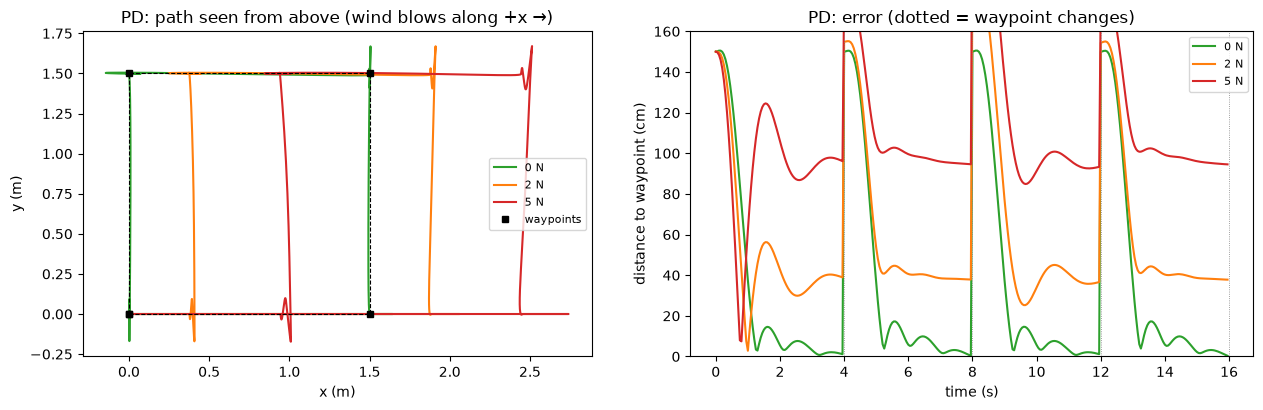

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for w in E.WINDS:
    lg = flight(f"pd_wind{w:g}")
    ax[0].plot(lg.x, lg.y, color=WIND_COLOURS[w], label=f"{w:.0f} N")
    ax[1].plot(lg.t, lg.err * 100, color=WIND_COLOURS[w], label=f"{w:.0f} N")
sq = np.vstack([sim.WAYPOINTS[:, :2]])
ax[0].plot(sq[:, 0], sq[:, 1], "k--", lw=0.8); ax[0].plot(sq[:, 0], sq[:, 1], "ks", ms=5, label="waypoints")
ax[0].set(xlabel="x (m)", ylabel="y (m)", title="PD: path seen from above (wind blows along +x →)", aspect="equal"); ax[0].legend(fontsize=8)
for k in range(1, 5): ax[1].axvline(4 * k, color="gray", lw=0.6, ls=":")
ax[1].set(xlabel="time (s)", ylabel="distance to waypoint (cm)", title="PD: error (dotted = waypoint changes)",
          ylim=(0, 160)); ax[1].legend(fontsize=8)
plt.tight_layout()

### 4b. PID: the integral removes the offset, but winds up in calm air

In [8]:
names = {"PD": "pd_wind{w:g}", "PID": "ki2_zoneinf_liminf_wind{w:g}", "PID near 0.5 m": "ki2_zone0.5_liminf_wind{w:g}"}
by_id = summary.set_index("id")
tab = pd.DataFrame({n: [by_id.loc[p.format(w=w), "mean_error_m"] * 100 for w in E.WINDS] for n, p in names.items()},
                   index=[f"{w:.0f} N" for w in E.WINDS])
tab.round(2).rename_axis("waypoint error (cm)")

,PD,PID,PID near 0.5 m
waypoint error (cm),,,
0 N,0.52,13.56,3.14
2 N,37.79,14.57,6.24
5 N,94.58,15.36,94.26


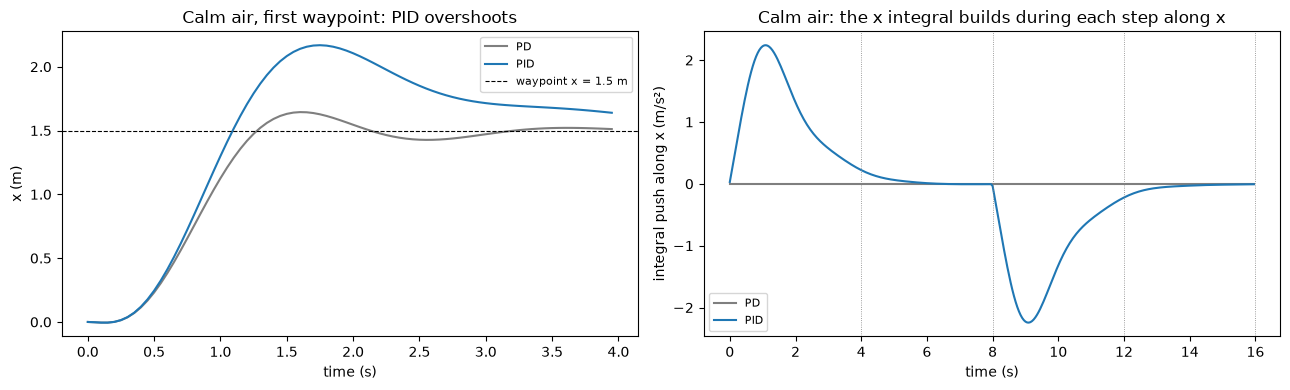

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, fid, c in [("PD", "pd_wind0", "tab:gray"), ("PID", "ki2_zoneinf_liminf_wind0", "tab:blue")]:
    lg = flight(fid)
    seg = lg[lg.t < 4.0]
    ax[0].plot(seg.t, seg.x, color=c, label=name)
    ax[1].plot(lg.t, lg.i_ax, color=c, label=name)
ax[0].axhline(1.5, color="k", ls="--", lw=0.8, label="waypoint x = 1.5 m")
ax[0].set(xlabel="time (s)", ylabel="x (m)", title="Calm air, first waypoint: PID overshoots"); ax[0].legend(fontsize=8)
for k in range(1, 5): ax[1].axvline(4 * k, color="gray", lw=0.6, ls=":")
ax[1].set(xlabel="time (s)", ylabel="integral push along x (m/s²)",
          title="Calm air: the x integral builds during each step along x"); ax[1].legend(fontsize=8)
plt.tight_layout()

### 4c. Integral only near the target
The integral only builds while the drone is within 0.5 m of the waypoint (shaded). In 5 N of wind the PD part
settles about 0.94 m away, outside the 0.5 m zone, so the integral never builds.

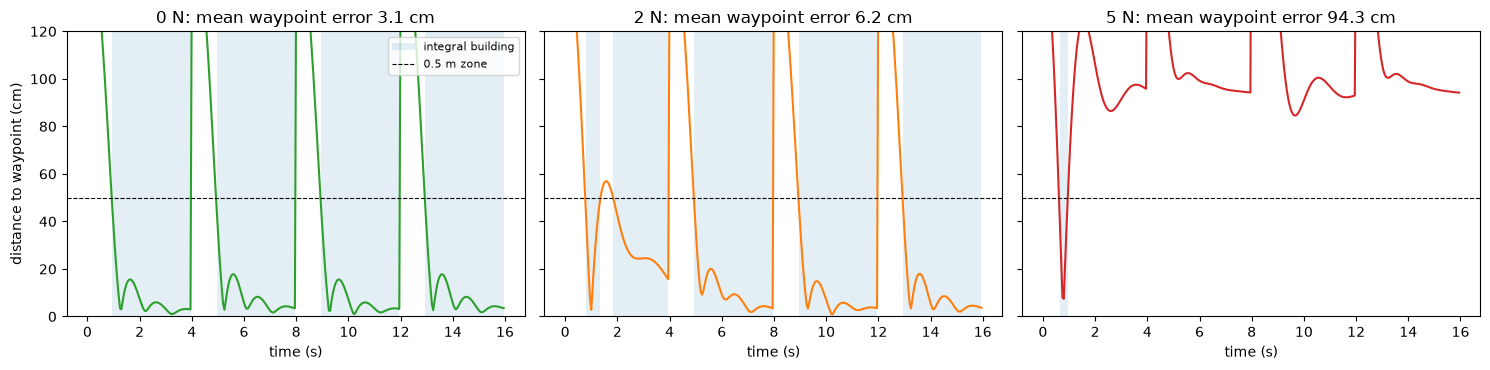

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, w in zip(ax, E.WINDS):
    lg = flight(f"ki2_zone0.5_liminf_wind{w:g}")
    a.plot(lg.t, lg.err * 100, color=WIND_COLOURS[w])
    a.fill_between(lg.t, 0, 120, where=lg.building.astype(bool), color="tab:blue", alpha=0.12, lw=0,
                   label="integral building")
    a.axhline(50, color="k", ls="--", lw=0.8, label="0.5 m zone")
    a.set(title=f"{w:.0f} N: mean waypoint error {by_id.loc[f'ki2_zone0.5_liminf_wind{w:g}', 'mean_error_m'] * 100:.1f} cm",
          xlabel="time (s)", ylim=(0, 120))
ax[0].set_ylabel("distance to waypoint (cm)"); ax[0].legend(fontsize=8, loc="upper right")
plt.tight_layout()

### 4d. The sweep
Mean waypoint error for every integral gain and "near" distance (no limit), in each wind. Red = worse; ✗ = crashed.

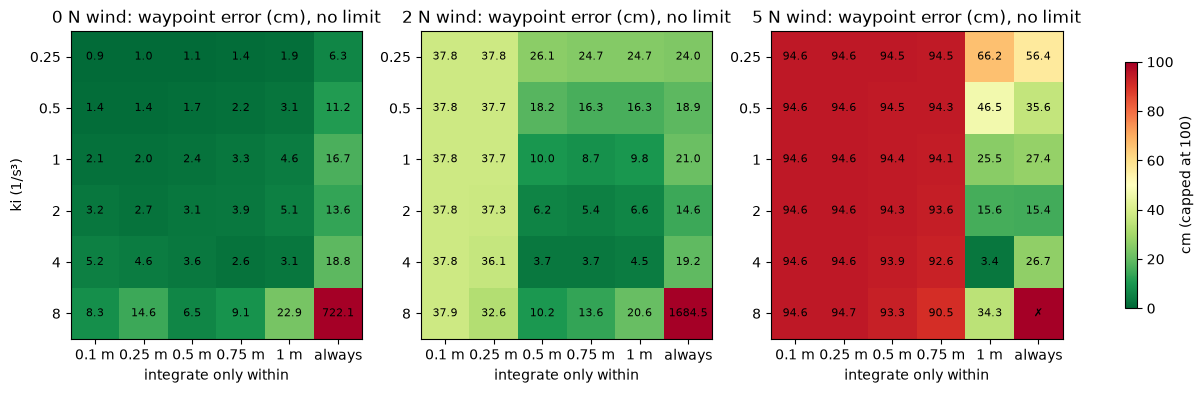

In [11]:
sw = summary[summary.ki > 0].copy()
sw["err_cm"] = sw.mean_error_m * 100
zones = list(E.ZONE_VALUES); zlab = [f"{z:g} m" if np.isfinite(z) else "always" for z in zones]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, w in zip(ax, E.WINDS):
    g = sw[(sw.wind_N == w) & np.isinf(sw.i_limit)].pivot(index="ki", columns="i_zone", values="err_cm")[zones]
    im = a.imshow(np.minimum(g.values, 100), cmap="RdYlGn_r", vmin=0, vmax=100, aspect="auto")
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g.values[i, j]
            a.text(j, i, "✗" if not np.isfinite(v) else f"{v:.1f}", ha="center", va="center", fontsize=8)
    a.set(xticks=range(len(zones)), xticklabels=zlab, yticks=range(len(g.index)), yticklabels=[f"{k:g}" for k in g.index],
          xlabel="integrate only within", title=f"{w:.0f} N wind: waypoint error (cm), no limit")
ax[0].set_ylabel("ki (1/s³)")
fig.colorbar(im, ax=ax, shrink=0.8, label="cm (capped at 100)")

**The limit.** The integral term can only cancel a wind up to `m × limit`. 5 N needs 5 / 1.325 = 3.8 m/s², so limits
of 1 and 2 m/s² leave part of the offset. Best error over all gains and zones, for each limit:

In [12]:
lim = sw.pivot_table(index="i_limit", columns="wind_N", values="err_cm", aggfunc="min")
lim.index = [f"{v:g} m/s²" if np.isfinite(v) else "none" for v in lim.index]
lim.columns = [f"{w:.0f} N" for w in lim.columns]
lim.round(2).rename_axis("best waypoint error (cm) with limit")

,0 N,2 N,5 N
best waypoint error (cm) with limit,,,
1 m/s²,0.91,13.19,69.36
2 m/s²,0.91,3.72,44.08
4 m/s²,0.91,3.72,3.78
8 m/s²,0.91,3.72,3.43
none,0.91,3.72,3.43


**Best setting in each wind, and the best all-round setting** (smallest worst-case error over the three winds).

In [13]:
p = sw.pivot_table(index=["ki", "i_zone", "i_limit"], columns="wind_N", values="err_cm")
p.columns = [f"{w:.0f} N" for w in p.columns]
p["worst"] = p.max(axis=1)
pdrow = pd.DataFrame([summary[summary.ki == 0].set_index("wind_N").mean_error_m.values * 100], columns=p.columns[:3],
                     index=pd.MultiIndex.from_tuples([(0.0, np.nan, np.nan)], names=p.index.names))
pdrow["worst"] = pdrow.max(axis=1)
allp = pd.concat([pdrow, p])
rows = {f"best at {c}": allp[c].idxmin() for c in ["0 N", "2 N", "5 N", "worst"]}
best = pd.DataFrame({k: allp.loc[v] for k, v in rows.items()}).T
best.insert(0, "setting (ki, zone m, limit m/s²)", [("PD" if v[0] == 0 else str(tuple(f"{x:g}" for x in v))) for v in rows.values()])
best.round(2)

,"setting (ki, zone m, limit m/s²)",0 N,2 N,5 N,worst
best at 0 N,PD,0.52,37.79,94.58,94.58
best at 2 N,"('4', '0.5', '2')",3.63,3.72,93.93,93.93
best at 5 N,"('4', '1', '8')",3.15,4.47,3.43,4.47
best at worst,"('4', '1', '4')",3.15,4.47,3.78,4.47


**Why one zone works in every wind.** The "near" distance has to satisfy two conditions at once:
- it must be *larger* than the offset the PD part settles at, `F / (m kp)`, or the integral never starts: 0.38 m at
  2 N and 0.94 m at 5 N;
- it must be *smaller* than the distance the drone travels between waypoints (1.5 m here), or the integral builds
  during every step and overshoots, as the always-on PID does.

Only 1.0 m in the grid satisfies both for 5 N. Without it, the sweep's best all-round setting is:

In [14]:
no1 = allp[~(allp.index.get_level_values("i_zone") == 1.0)].sort_values("worst").head(3)
no1.round(2)

0 N    2 N    5 N  worst
ki  i_zone i_limit                            
2.0 inf    4.0      13.56  14.57  12.35  14.57
           8.0      13.56  14.57  15.36  15.36
           inf      13.56  14.57  15.36  15.36

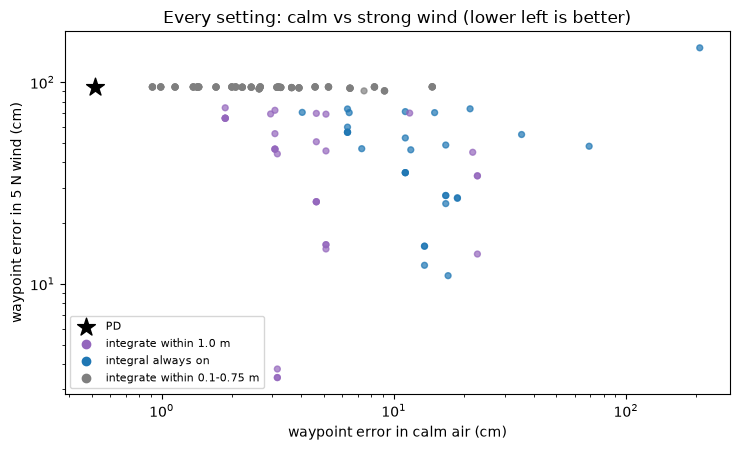

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ok = p[np.isfinite(p["worst"])]
c = ["tab:purple" if z == 1.0 else ("tab:blue" if np.isinf(z) else "tab:gray") for z in ok.index.get_level_values("i_zone")]
ax.scatter(ok["0 N"], ok["5 N"], c=c, s=18, alpha=0.7)
ax.scatter(allp.loc[(0.0, np.nan, np.nan), "0 N"], allp.loc[(0.0, np.nan, np.nan), "5 N"], marker="*", s=180,
           color="k", label="PD")
for col, lab in [("tab:purple", "integrate within 1.0 m"), ("tab:blue", "integral always on"),
                 ("tab:gray", "integrate within 0.1-0.75 m")]:
    ax.scatter([], [], color=col, label=lab)
ax.set(xscale="log", yscale="log", xlabel="waypoint error in calm air (cm)", ylabel="waypoint error in 5 N wind (cm)",
       title="Every setting: calm vs strong wind (lower left is better)")
ax.legend(fontsize=8); plt.tight_layout()

### 4e. The best all-round setting in flight

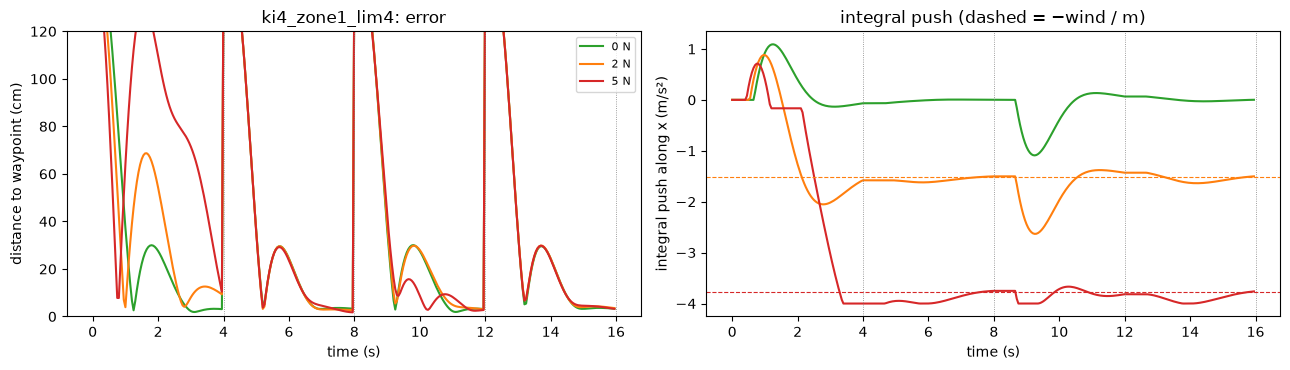

In [16]:
bk = rows["best at worst"]
fid = "ki{}_zone{}_lim{}".format(*[E._num(v) for v in bk])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for w in E.WINDS:
    lg = flight(f"{fid}_wind{w:g}")
    ax[0].plot(lg.t, lg.err * 100, color=WIND_COLOURS[w], label=f"{w:.0f} N")
    ax[1].plot(lg.t, lg.i_ax, color=WIND_COLOURS[w], label=f"{w:.0f} N")
for a in ax:
    for k in range(1, 5): a.axvline(4 * k, color="gray", lw=0.6, ls=":")
ax[1].axhline(-5 / mass, color="tab:red", ls="--", lw=0.8); ax[1].axhline(-2 / mass, color="tab:orange", ls="--", lw=0.8)
ax[0].set(xlabel="time (s)", ylabel="distance to waypoint (cm)", ylim=(0, 120), title=f"{fid}: error")
ax[1].set(xlabel="time (s)", ylabel="integral push along x (m/s²)", title="integral push (dashed = −wind / m)")
ax[0].legend(fontsize=8); plt.tight_layout()

### 4f. How much wind can each setting take?
The sweep only tried 0, 2 and 5 N. Here three settings fly the same mission at every wind from 0 to 8 N in 0.5 N
steps (computed here, about 10 s; not saved to `data/`).

,0.0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0,6.5,7.0,7.5,8.0
PD,0.5,9.4,18.9,28.3,37.8,47.2,56.7,66.1,75.6,85.0,94.6,104.2,113.8,123.5,133.1,142.4,151.0
"best all-round (ki 4, within 1.0 m, limit 4)",3.1,3.5,3.8,4.1,4.5,4.8,5.1,5.4,4.7,3.4,3.8,10.8,113.3,123.5,133.9,143.3,152.3
"PID always on (ki 2, limit 8)",13.6,13.8,14.1,14.3,14.6,14.8,15.1,15.3,15.6,15.6,15.4,14.5,12.6,14.4,22.4,28.7,25.4


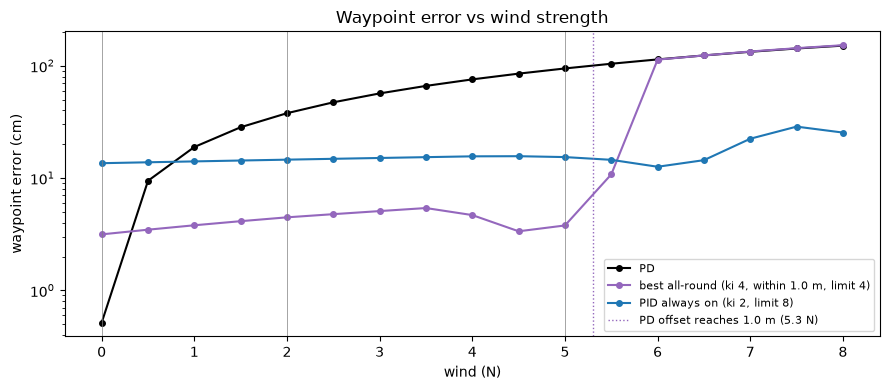

In [17]:
settings = {"PD": E.PD, "best all-round (ki 4, within 1.0 m, limit 4)": E.make_gains(4.0, 1.0, 4.0),
            "PID always on (ki 2, limit 8)": E.make_gains(2.0, np.inf, 8.0)}
winds = np.arange(0.0, 8.01, 0.5)
margin = pd.DataFrame({name: [np.inf if (r := sim.fly(g, w, model)[1])["crashed"] else np.mean(r["end_errors_m"]) * 100
                              for w in winds] for name, g in settings.items()}, index=winds)
fig, ax = plt.subplots(figsize=(9, 4))
for (name, col), c in zip(margin.items(), ["k", "tab:purple", "tab:blue"]):
    ax.plot(winds, col, "o-", ms=4, color=c, label=name)
ax.axvline(1.0 * mass * sim.Gains.kp, color="tab:purple", ls=":", lw=1, label="PD offset reaches 1.0 m (5.3 N)")
for w in E.WINDS: ax.axvline(w, color="gray", lw=0.5)
ax.set(yscale="log", xlabel="wind (N)", ylabel="waypoint error (cm)", title="Waypoint error vs wind strength")
ax.legend(fontsize=8); plt.tight_layout()
margin.T.round(1)

## 5. Results
**PD leaves the offset the formula predicts.** In calm air the waypoint error is 0.5 cm, the drone still swaying by a
few millimetres when the 4 s are up. In wind it settles short of each waypoint and stays there: 37.8 cm at 2 N
(predicted 37.7 cm) and 94.6 cm at 5 N (predicted 94.3 cm). The PD pushes back by `m·kp·e`, so the error grows until
that push equals the wind.

**The always-on integral removes the offset but costs accuracy in calm air.** PID (ki 2) holds 14.6 cm at 2 N and
15.4 cm at 5 N, but in calm air the error rises from 0.5 to 13.6 cm. The integral builds during each 1.5 m step,
when the error is large, so the drone overshoots and the stored push takes several seconds to unwind. That is still
not over when the 4 s are up.

**Integrating only near the target fixes calm air but has a blind spot.** With a 0.5 m zone the calm error drops to
3.1 cm and 2 N gives 6.2 cm. At 5 N the PD part settles 0.94 m away, outside the zone, so the integral never builds
and the error stays at 94.3 cm, the same as plain PD.

**The sweep: each knob has a hard threshold.**
- The **zone** must be larger than the PD offset `F / (m kp)`: above 0.38 m for 2 N and above 0.94 m for 5 N.
  Every zone of 0.75 m or less stays above 90 cm at 5 N.
- The **limit** must be at least `F / m`: 1.5 m/s² for 2 N and 3.8 m/s² for 5 N. Limits of 1 and 2 m/s² leave
  69 and 44 cm at 5 N.
- An always-on integral that is too strong is unstable: with ki 8 it drifts off by metres, and at 5 N it crashes.
  This was the only crash in the sweep.

**The best all-round setting** is ki 4, integrating within 1.0 m, limit 4 m/s² or more: 3.2 cm calm, 4.5 cm at
2 N and 3.4-3.8 cm at 5 N. It works because 1.0 m is larger than the 0.94 m offset at 5 N but smaller than the 1.5 m
waypoint step, so the integral stays off during the steps. Without the 1.0 m zone the best all-round setting is the
always-on PID with limit 4: 13.6 / 14.6 / 12.4 cm.

**But that margin is thin, and the conflict is still there.** The best setting has only 6 cm between the zone and
the 5 N offset. Above 5.3 N the offset is larger than 1.0 m: at 6 N the error jumps to 113 cm, while the always-on
PID still holds 12.6-15.6 cm up to 6.5 N. And no setting that handles 5 N comes close to PD's 0.5 cm in calm air; the
best is 3.2 cm. Settings that are good in light wind fail in strong wind, and the other way
round.


## Conclusion
- The I term in PID is there for exactly this reason: PD alone can't hold a waypoint against a steady force, and the
  error is just `F / (m kp)`.
- An integral that is always on pays for this with overshoot after every large move. Conditions that stop it from
  building (a zone, a limit) help, but each one sets a wind beyond which it fails. The zone must cover the offset,
  and the limit must cover `F / m`.
- No single fixed setting was best in calm, light and strong wind: the best all-round setting here is good up to
  about 5.3 N and then fails badly. Fixing this would take something that does not depend on a fixed distance, for
  example an integral that winds down during large moves, or a wind estimate fed forward. This is also the kind
  of trade-off a learned controller could pick up.

**Limitations:**
- One mission (1.5 m square, 4 s holds), and the wind is a constant force along x, with no gusts or turbulence.
- The true state is used, with no sensor noise.
- No motor lag.
- One kp/kd pair: kp 4 with kd 3.
- The error is measured at a single moment per waypoint.

In [18]:
m = json.loads((DATA / "manifest.json").read_text())
print("git revision:", m.get("git_revision"), "| MuJoCo", m["versions"]["mujoco"], "| numpy", m["versions"]["numpy"],
      "| Python", m["python"])
print("sessions:", [s["finished"] for s in m["sessions"]])

git revision: 02e6e60 | MuJoCo 3.16.0 | numpy 2.5.4 | Python 3.13.9
sessions: ['2026-11-05T23:47:22', '2026-11-05T23:49:10', '2026-11-05T23:50:33', '2026-11-05T23:52:16']
